In [55]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as wf;
import pycbc.types as tps;
import pycbc.detector as detector;

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'

order="5l" 

import numpy as np
# 双精度浮点数（Python float 类型）的机器epsilon
eps = np.finfo(np.float64).eps
print(eps)  # 输出约 2.220446049250313e-16

2.220446049250313e-16


In [56]:
events = dict(
    mass1 = 37.33,
    mass2 = 10,
    spin1z = 0.4528,
    spin2z = -0.2424,
    distance = 443.41,
    inclination = 1.32,
    coa_phase = 2.7,
    ra = 2.32,
    delta_t = -0.02247,

    f_lower = 20,
    delta_f = 1/16,
    f_final = 2048,
    f_ref=20
)
events = dict(
    mass1 = 37.33,
    mass2 = 31.30,
    spin1z = 0.06424,
    spin2z = 0.08528,
    distance = 443.41,
    inclination = 2.21,
    coa_phase = 3.33,
    ra = 2.32,
    delta_t = -0.02247,

    f_lower = 20,
    delta_f = 1/16,
    f_final = 2048,
    f_ref=20
)


hphc = {}
psi_values = {
    "0": 8547.017947189588,
    "2": 572.0511301750156,
    "3": -435.2655900877971,
    "4": 42.43897564657722,
    "5l": 12.927784161810335,
    "6": -3.1981519519601536,
    "6l": -1.0477667816841614,
    "7": 0.12035041449230943
}


# psi_values = {
#     "0": 7807.855091891816,
#     "2": 581.3260533328929,
#     "3": -476.6588409813518,
#     "4": 47.92669187130613,
#     "5l": 13.153061755655974,
#     "6": 2.277386824803785,
#     "6l": -1.6460338999551067,
#     "7": -1.7079292402190283
# }


deltas = [-1,-0.8,-0.6,-0.4,-0.2,0,0.2,0.4,0.6,0.8,1]

deltas = [-0.6,-0.3,0,0.3,0.6]

tmpWF = WF.IMRPhenomXAS()
fcut = tmpWF.fcut(**events|{"Mc": np.array([cvs.mchirp_from_mass1_mass2(events['mass1'],events['mass2'])]), "eta": np.array([cvs.eta_from_mass1_mass2(events['mass1'],events['mass2'])])})
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

cpsijs = ['gr', 'cpsi0', 'cpsi2', 'cpsi3', 'cpsi4', 'cpsi5l', 'cpsi6', 'cpsi6l', 'cpsi7']
dchis = ['gr', 'dchi0', 'dchi2', 'dchi3', 'dchi4', 'dchi5l', 'dchi6', 'dchi6l', 'dchi7']
orders = ['gr', '0', '2', '3', '4', '5l', '6', '6l', '7']

hp_gr, hc_gr = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    coa_phase=events["coa_phase"],
                                                    # long_asc_nodes=events["long_asc_nodes"],
                                                    # mean_per_ano=events["mean_per_ano"],
                                                    )

hp_gr1, hc_gr1 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass2'],
                                                    mass2=events['mass1'],
                                                    spin1z=events['spin2z'],
                                                    spin2z=events['spin1z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    coa_phase=events["coa_phase"],
                                                    # long_asc_nodes=events["long_asc_nodes"],
                                                    # mean_per_ano=events["mean_per_ano"],
                                                    )

# hp_gr_test, hc_gr_test = wf.get_fd_waveform(approximant='test_IMRPhenomXAS',
#                                                     mass1=events['mass2'],
#                                                     mass2=events['mass1'],
#                                                     spin1z=events['spin2z'],
#                                                     spin2z=events['spin1z'],
#                                                     delta_f=events["delta_f"],
#                                                     distance=events['distance'],
#                                                     # mode_array = [[2,-2]],
#                                                     inclination=events['inclination'],
#                                                     f_final=events['f_final'],
#                                                     f_lower=events["f_lower"],
#                                                     f_ref=events["f_ref"],
#                                                     coa_phase=events["coa_phase"],
#                                                     long_asc_nodes=events["long_asc_nodes"],
#                                                     mean_per_ano=events["mean_per_ano"],
#                                                     )

hp_gr_my, hc_gr_my = wf.get_fd_waveform(**{
            'approximant': 'dchi_modified_IMRPhenomXAS',
            'mass1': events['mass1'],
            'mass2': events['mass2'],
            'spin1z': events['spin1z'],
            'spin2z': events['spin2z'],
            'delta_f': events["delta_f"],
            'distance': events['distance'],
            # 'mode_array': [[2, -2]],
            'inclination': events['inclination'],
            'f_final': events['f_final'],
            'f_lower': events["f_lower"],
            'f_ref': events["f_ref"],
            'coa_phase': events["coa_phase"],
            # 'long_asc_nodes':events["long_asc_nodes"],
            # 'mean_per_ano':events["mean_per_ano"],
            # 'dchi'+o: psi_values[o] * (1 + delta),
            # 'if_dchi0': (o == "0"),
            # 'if_dchi1': (o == "1"),
            # 'if_dchi2': (o == "2"),
            # 'if_dchi3': (o == "3"),
            # 'if_dchi4': (o == "4"),
            # 'if_dchi5l': (o == "5l"),
            # 'if_dchi5': (o == "5"),
            # 'if_dchi6': (o == "6"),
            # 'if_dchi6l': (o == "6l"),
            # 'if_dchi7': (o == "7"),
            # 'if_dchi8': (o == "8"),
            # 'if_dchi8l': (o == "8l"),
        })



/tmp/ipykernel_1546759/409173355.py:68: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)


In [57]:
len(hp_gr)

32769

In [58]:
for o in orders :
    if o == "gr" :
        hphc[o] = [wf.get_fd_waveform(**{
            'approximant': 'dchi_modified_IMRPhenomXAS',
            'mass1': events['mass1'],
            'mass2': events['mass2'],
            'spin1z': events['spin1z'],
            'spin2z': events['spin2z'],
            'delta_f': events["delta_f"],
            'distance': events['distance'],
            # 'mode_array': [[2, -2]],
            'inclination': events['inclination'],
            'f_final': events['f_final'],
            'f_lower': events["f_lower"],
            'f_ref': events["f_ref"],
            'coa_phase': events["coa_phase"],
            # 'long_asc_nodes':events["long_asc_nodes"],
            # 'mean_per_ano':events["mean_per_ano"],
            # 'dchi'+o: psi_values[o] * (1 + delta),
            # 'if_dchi0': (o == "0"),
            # 'if_dchi1': (o == "1"),
            # 'if_dchi2': (o == "2"),
            # 'if_dchi3': (o == "3"),
            # 'if_dchi4': (o == "4"),
            # 'if_dchi5l': (o == "5l"),
            # 'if_dchi5': (o == "5"),
            # 'if_dchi6': (o == "6"),
            # 'if_dchi6l': (o == "6l"),
            # 'if_dchi7': (o == "7"),
            # 'if_dchi8': (o == "8"),
            # 'if_dchi8l': (o == "8l"),
        }) for delta in deltas]
        for s in orders :
            print(f"{o}, {s}: {o == s}")
        continue
    hphc[o] = [wf.get_fd_waveform(**{
        'approximant': 'dchi_modified_IMRPhenomXAS',
        'mass1': events['mass1'],
        'mass2': events['mass2'],
        'spin1z': events['spin1z'],
        'spin2z': events['spin2z'],
        'delta_f': events["delta_f"],
        'distance': events['distance'],
        # 'mode_array': [[2, -2]],
        'inclination': events['inclination'],
        'f_final': events['f_final'],
        'f_lower': events["f_lower"],
        'f_ref': events["f_ref"],
        'coa_phase': events["coa_phase"],
        # 'long_asc_nodes':events["long_asc_nodes"],
        # 'mean_per_ano':events["mean_per_ano"],
        'dchi'+o: psi_values[o] * (1 + delta),
        'if_dchi0': (o == "0"),
        'if_dchi1': (o == "1"),
        'if_dchi2': (o == "2"),
        'if_dchi3': (o == "3"),
        'if_dchi4': (o == "4"),
        'if_dchi5l': (o == "5l"),
        'if_dchi5': (o == "5"),
        'if_dchi6': (o == "6"),
        'if_dchi6l': (o == "6l"),
        'if_dchi7': (o == "7"),
        'if_dchi8': (o == "8"),
        'if_dchi8l': (o == "8l"),
    }) for delta in deltas]
    np.save(f"./hphc/GW150914_like_{o}", hphc[o]);

gr, gr: True
gr, 0: False
gr, 2: False
gr, 3: False
gr, 4: False
gr, 5l: False
gr, 6: False
gr, 6l: False
gr, 7: False


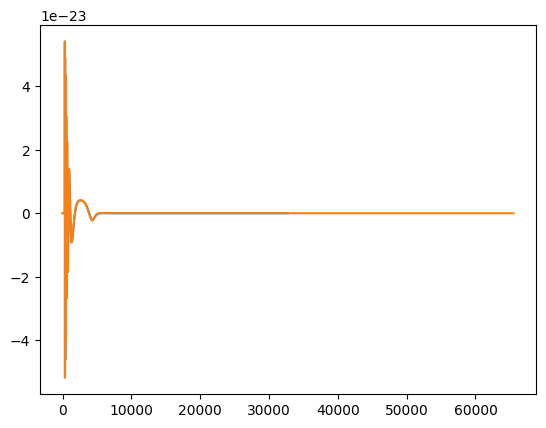

In [59]:
pp.plot(hp_gr.data)
pp.plot(hp_gr_my.data)

In [60]:
pp.plot(hp_gr.data/np.linalg.norm(hp_gr.data)-hp_gr_my.data/np.linalg.norm(hp_gr_my.data))

ValueError: operands could not be broadcast together with shapes (32769,) (65537,) 

In [ ]:
1 - np.real(np.conj(hp_gr.data/np.linalg.norm(hp_gr.data)) @ hp_gr_my.data/np.linalg.norm(hp_gr_my.data))

1.6910149352789006e-05

In [ ]:
from pycbc.waveform import get_td_waveform
from pycbc.filter import match
from pycbc.psd import aLIGOZeroDetHighPower

f_low = 30
sample_rate = 4096


psd = aLIGOZeroDetHighPower(len(hp_gr.sample_frequencies.data), events["delta_f"], 0)

# Note: This takes a while the first time as an FFT plan is generated
# subsequent calls are much faster.
m, i = match(hp_gr, hp_gr_my, psd=psd, low_frequency_cutoff=f_low)
print('The match is: {:.20f}'.format(m))

The match is: 0.99998977074607353632


In [ ]:
hp_gr.data/np.linalg.norm(hp_gr.data) @ hp_gr.data/np.linalg.norm(hp_gr.data)

(-0.024404555066731615+0.04391922154381797j)

In [ ]:
np.linalg.norm(hp_gr.data)

6.098512031069054e-22

In [ ]:
vars(hp_gr)

{'_scheme': <pycbc.scheme.DefaultScheme at 0x7fe4e58547d0>,
 '_saved': LimitedSizeDict([('slice(480, 32768, None)',
                   <pycbc.types.frequencyseries.FrequencySeries at 0x7fe4dddff210>)]),
 '_data': array([0.-0.j, 0.-0.j, 0.-0.j, ..., 0.-0.j, 0.-0.j, 0.-0.j]),
 '_delta_f': 0.0625,
 '_epoch': LIGOTimeGPS(-16, 0)}

In [ ]:
vars(hp_gr_my)

{'_scheme': <pycbc.scheme.DefaultScheme at 0x7fe4e58547d0>,
 '_saved': LimitedSizeDict([('slice(480, 32768, None)',
                   <pycbc.types.frequencyseries.FrequencySeries at 0x7fe4ddacf250>)]),
 '_data': array([0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j]),
 '_delta_f': 0.0625,
 '_epoch': LIGOTimeGPS(-16, 0)}

In [ ]:
# hp_gr.data = [1]
# hp_gr_my.data = [11]

In [ ]:
from deepdiff import DeepDiff
diff = DeepDiff(hp_gr, hp_gr_my)
print(diff)  # {'iterable_item_added': {'root.tags': [2, '入门']}}
print(bool(diff))  # True：存在差异

{'values_changed': {"root._saved['slice(480, 32768, None)']._data[0]": {'new_value': (-2.506191318889016e-23+5.202843089761532e-24j), 'old_value': (-2.5095191172310978e-23+5.039884409271651e-24j)}, "root._saved['slice(480, 32768, None)']._data[1]": {'new_value': (-2.539006751551941e-23+2.6306567359044798e-24j), 'old_value': (-2.5406742415134209e-23+2.464408482716776e-24j)}, "root._saved['slice(480, 32768, None)']._data[2]": {'new_value': (-2.5455943217827455e-23+6.181102511281565e-26j), 'old_value': (-2.545579718854405e-23-1.0602502244997625e-25j)}, "root._saved['slice(480, 32768, None)']._data[3]": {'new_value': (-2.5265175813433814e-23-2.4776333390107248e-24j), 'old_value': (-2.524816536807618e-23-2.645355850022755e-24j)}, "root._saved['slice(480, 32768, None)']._data[4]": {'new_value': (-2.4825841460378628e-23-4.96285924605671e-24j), 'old_value': (-2.4792094063760333e-23-5.1287848764403765e-24j)}, "root._saved['slice(480, 32768, None)']._data[5]": {'new_value': (-2.4148255169864532e

In [ ]:
diff['values_changed']

{"root._saved['slice(480, 32768, None)']._data[0]": {'new_value': (-2.506191318889016e-23+5.202843089761532e-24j),
  'old_value': (-2.5095191172310978e-23+5.039884409271651e-24j)},
 "root._saved['slice(480, 32768, None)']._data[1]": {'new_value': (-2.539006751551941e-23+2.6306567359044798e-24j),
  'old_value': (-2.5406742415134209e-23+2.464408482716776e-24j)},
 "root._saved['slice(480, 32768, None)']._data[2]": {'new_value': (-2.5455943217827455e-23+6.181102511281565e-26j),
  'old_value': (-2.545579718854405e-23-1.0602502244997625e-25j)},
 "root._saved['slice(480, 32768, None)']._data[3]": {'new_value': (-2.5265175813433814e-23-2.4776333390107248e-24j),
  'old_value': (-2.524816536807618e-23-2.645355850022755e-24j)},
 "root._saved['slice(480, 32768, None)']._data[4]": {'new_value': (-2.4825841460378628e-23-4.96285924605671e-24j),
  'old_value': (-2.4792094063760333e-23-5.1287848764403765e-24j)},
 "root._saved['slice(480, 32768, None)']._data[5]": {'new_value': (-2.4148255169864532e-23-

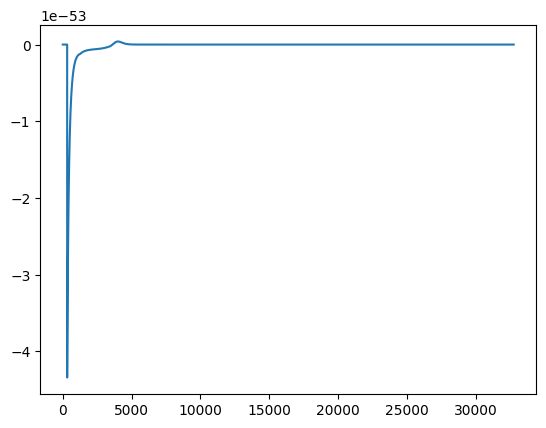

In [ ]:
pp.plot(hp_gr.squared_norm().data-hp_gr_my.squared_norm().data)
# pp.plot()

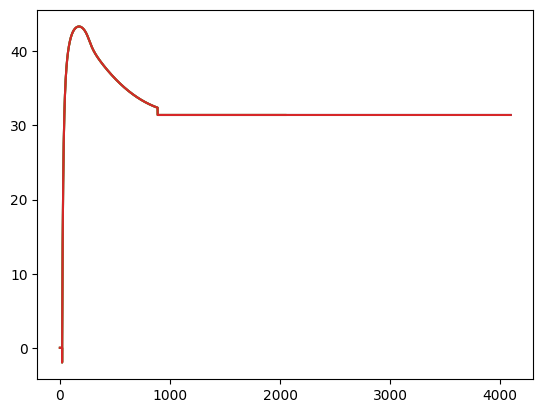

In [68]:
i = 2
o = "6l"
pp.plot(hphc[o][i][0].sample_frequencies, np.unwrap(np.angle(hphc[o][i][0].data)));
pp.plot(hp_gr.sample_frequencies, np.unwrap(np.angle(hp_gr.data)));
pp.plot(hp_gr1.sample_frequencies, np.unwrap(np.angle(hp_gr1.data)));
pp.plot(hp_gr_my.sample_frequencies, np.unwrap(np.angle(hp_gr_my.data)));


In [ ]:
np.unwrap(np.angle(hp_gr_my.data)) - np.unwrap(np.angle(hp_gr.data))+np.pi

array([3.14159265, 3.14159265, 3.14159265, ..., 3.14159265, 3.14159265,
       3.14159265])

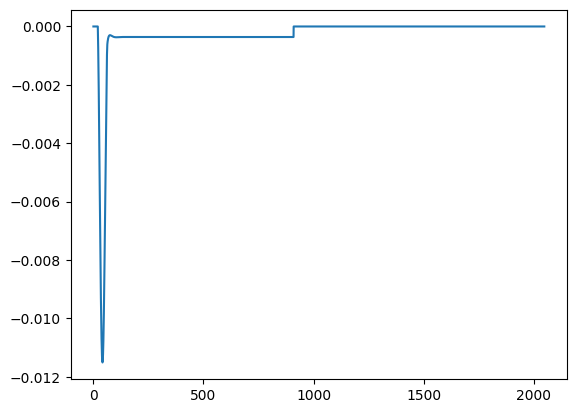

In [ ]:
pp.plot(hp_gr_my.sample_frequencies, np.unwrap(np.angle(hphc[o][i][0].data))-np.unwrap(np.angle(hp_gr.data)));


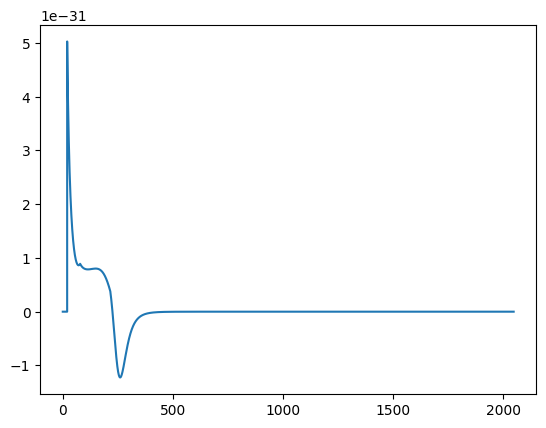

In [ ]:
pp.plot(hp_gr_my.sample_frequencies, np.abs(hphc[o][i][0].data)-np.abs(hp_gr.data));


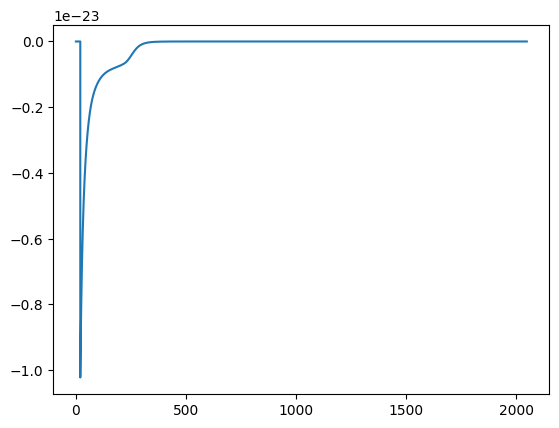

In [ ]:
pp.plot(hc_gr_my.sample_frequencies, np.abs(hphc[o][i][1].data)-np.abs(hp_gr.data));


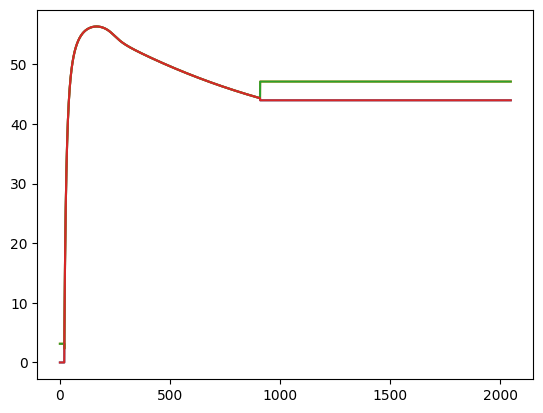

In [ ]:
i = 2
o = "gr"
pp.plot(hphc[o][i][1].sample_frequencies, np.unwrap(np.angle(hphc[o][i][1].data)));
pp.plot(hc_gr.sample_frequencies, np.unwrap(np.angle(hc_gr.data)));
pp.plot(hc_gr1.sample_frequencies, np.unwrap(np.angle(hc_gr1.data)));
pp.plot(hc_gr_my.sample_frequencies, np.unwrap(np.angle(hc_gr_my.data)));


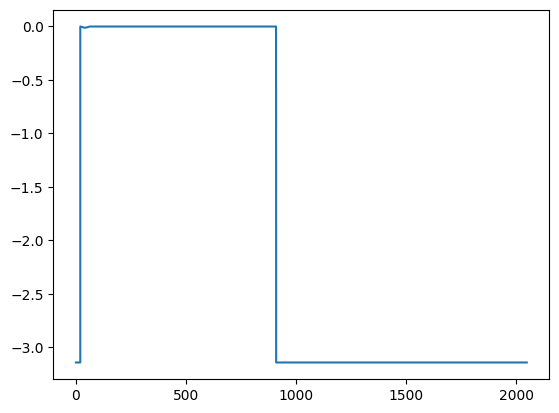

In [ ]:
pp.plot(hphc[o][i][1].sample_frequencies, np.unwrap(np.angle(hphc[o][i][1].data)-np.angle(hc_gr.data)))

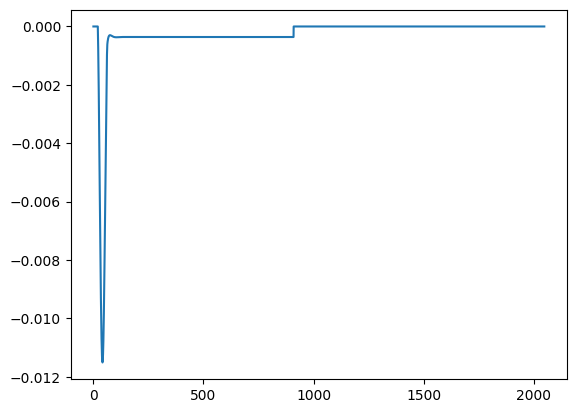

In [ ]:
pp.plot(hphc[o][i][0].sample_frequencies, np.unwrap(np.angle(hphc[o][i][0].data)-np.angle(hp_gr.data)))

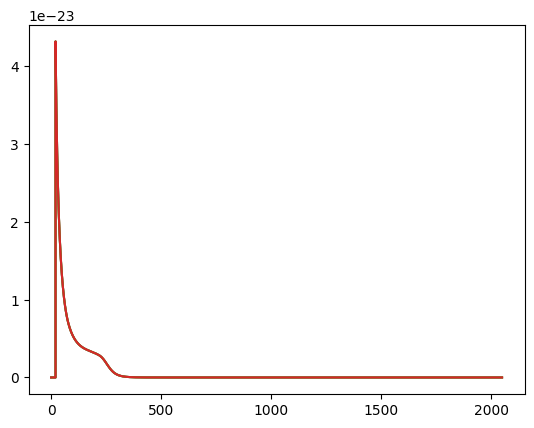

In [ ]:
pp.plot(hp_gr.sample_frequencies, np.abs(hp_gr.data));
pp.plot(hp_gr1.sample_frequencies, np.abs(hp_gr1.data));
pp.plot(hp_gr_my.sample_frequencies, np.abs(hp_gr_my.data));
pp.plot(hphc[o][i][0].sample_frequencies, np.abs(hphc[o][i][0].data));

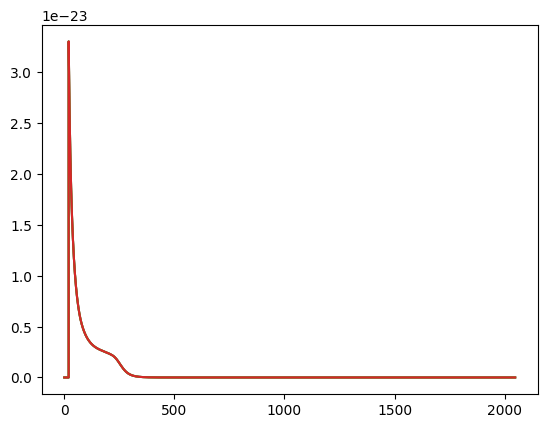

In [ ]:
pp.plot(hc_gr.sample_frequencies, np.abs(hc_gr.data));
pp.plot(hc_gr1.sample_frequencies, np.abs(hc_gr1.data));
pp.plot(hc_gr_my.sample_frequencies, np.abs(hc_gr_my.data));
pp.plot(hphc[o][i][1].sample_frequencies, np.abs(hphc[o][i][1].data));

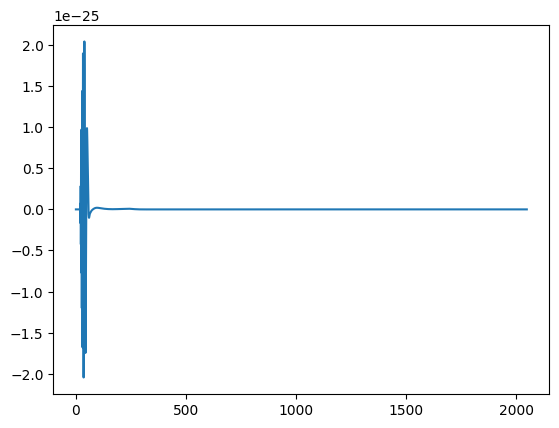

In [ ]:
i = 2
o = "gr"
pp.plot(hp_gr.sample_frequencies, np.imag(hp_gr.data)-np.imag(hp_gr_my.data))


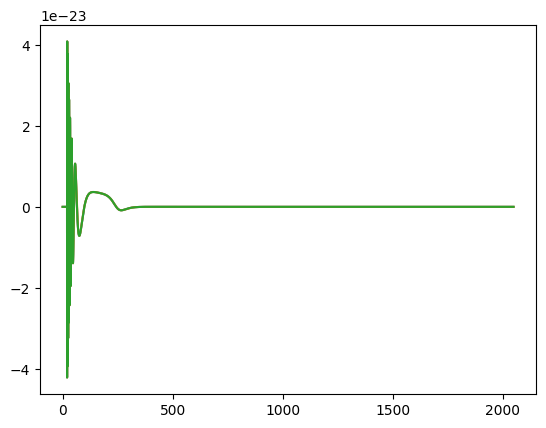

In [ ]:
i = 2
o = "gr"
pp.plot(hphc[o][i][0].sample_frequencies, np.imag(hphc[o][i][0].data))
pp.plot(hp_gr.sample_frequencies, np.imag(hp_gr.data))
pp.plot(hp_gr_my.sample_frequencies, np.imag(hp_gr_my.data))

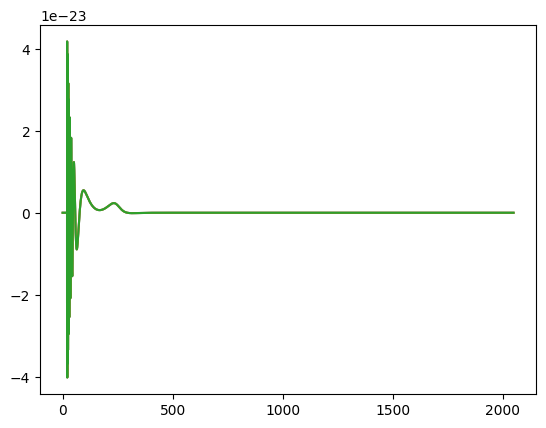

In [ ]:
i = 2
o = "gr"
pp.plot(hphc[o][i][0].sample_frequencies, np.real(hphc[o][i][0].data))
pp.plot(hp_gr.sample_frequencies, np.real(hp_gr.data))
pp.plot(hp_gr_my.sample_frequencies, np.real(hp_gr_my.data))

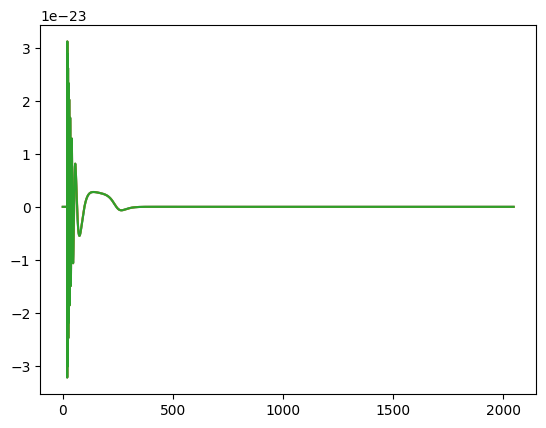

In [ ]:
i = 2
o = "gr"
pp.plot(hphc[o][i][1].sample_frequencies, np.real(hphc[o][i][1].data))
pp.plot(hc_gr.sample_frequencies, np.real(hc_gr.data))
pp.plot(hc_gr_my.sample_frequencies, np.real(hc_gr_my.data))

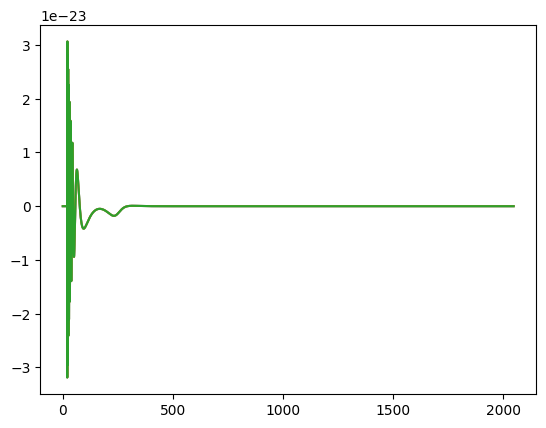

In [ ]:
i = 2
o = "gr"
pp.plot(hphc[o][i][1].sample_frequencies, np.imag(hphc[o][i][1].data))
pp.plot(hc_gr.sample_frequencies, np.imag(hc_gr.data))
pp.plot(hc_gr_my.sample_frequencies, np.imag(hc_gr_my.data))

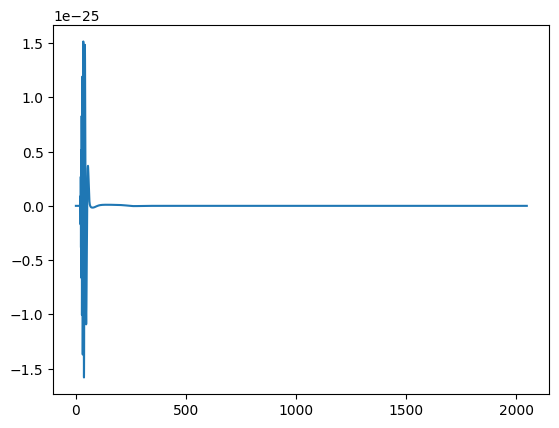

In [ ]:
pp.plot(hc_gr_my.sample_frequencies, np.imag(hc_gr.data)-np.imag(hphc[o][i][1].data))